# Unsupervised Color-Based Clustering of TV Show Posters with IMDb Metadata Analysis

In [25]:
import os
import random
import requests
import numpy as np
import pandas as pd
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import warnings
warnings.filterwarnings('ignore')

In [26]:
def get_random_images(filepath, n=100):
    """Select n random images from the specified directory."""
    all_images = [f for f in os.listdir(filepath) if f.startswith('tt')]
    return random.sample(all_images, min(n, len(all_images)))

In [27]:
def extract_imdb_id(filename):
    """Extract IMDB ID from filename."""
    return filename.split('.')[0]

In [28]:
def get_imdb_data(imdb_id):
    """Fetch and parse IMDB page data."""
    url = f'https://www.imdb.com/title/{imdb_id}/'
    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36"}

    
    try:
        response = requests.get(url, headers=headers)
        soup = BeautifulSoup(response.text, 'html.parser')
        script = soup.find('script', {'type': 'application/ld+json'})
        if not script:
            return None
        
        import json
        data = json.loads(script.string)
        
        show_data = {
            'imdb_id': imdb_id,
            'title': data.get('name', ''),
            'rating': data.get('aggregateRating', {}).get('ratingValue', 0),
            'rating_count': data.get('aggregateRating', {}).get('ratingCount', 0),
            'content_rating': data.get('contentRating', ''),
            'date_published': data.get('datePublished', ''),
            'genres': data.get('genre', [])  # Now storing the full list of genres
        }
        
        return show_data
    except Exception as e:
        print(f"Error processing {imdb_id}: {str(e)}")
        return None

In [29]:
def extract_color_features(image_path):
    """Extract color histogram features from image."""
    img = cv2.imread(image_path)
    if img is None:
        return None
    
    # Resize for consistency
    img_resized = cv2.resize(img, (224, 336))
    
    # Convert to RGB
    img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
    
    # Calculate RGBW values 
    features = {}
    r, g, b = cv2.split(img_rgb)
    w = (r + g + b) / 3  # White component as average of RGB
    features = np.array([r.mean(), g.mean(), b.mean(), w.mean()])
    
    return features

In [30]:
def create_dataset(image_folder):
    """Create datasets from images and their analysis."""
    images = get_random_images(image_folder)
    imdb_data = []
    feature_data = []
    
    for img in images:
        imdb_id = extract_imdb_id(img)
        show_data = get_imdb_data(imdb_id)
        
        if show_data:
            img_path = os.path.join(image_folder, img)
            features = extract_color_features(img_path)

            if features is not None:  # Ensure features is not empty
                # Append imdb_id to the features array (assuming features is a 1D array)
                features_with_id = np.append(features, imdb_id)  # Append imdb_id to the features
                feature_data.append(features_with_id)
                imdb_data.append(show_data)
    
    # Define column names for the feature DataFrame
    feature_columns = ['r_mean', 'g_mean', 'b_mean', 'w_mean', 'imdb_id']
    
    imdb_df = pd.DataFrame(imdb_data)
    feature_df = pd.DataFrame(feature_data, columns=feature_columns)
    
    # Save datasets
    imdb_df.to_csv('imdb_data.csv', index=False)
    feature_df.to_csv('feature_data.csv', index=False)
    
    return imdb_df, feature_df

In [31]:
def perform_pca_analysis(feature_df):
    # Prepare feature matrix
    X = feature_df.drop('imdb_id', axis=1)
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Perform PCA with only 2 components
    pca = PCA(n_components=2)  # Explicitly set to 2 components
    X_pca = pca.fit_transform(X_scaled)
    
    # Get cumulative variance ratio
    cum_var_ratio = np.cumsum(pca.explained_variance_ratio_)
    
    # Since we're only using 2 components, n_components is fixed at 2
    n_components = 2
    
    return pca, X_pca, n_components

In [32]:
def plot_explained_variance(pca, n_components):
    """Plot explained variance ratio as a bar graph up to n_components."""
    explained_variance = pca.explained_variance_ratio_[:n_components]  # Limit to n_components
    
    plt.figure(figsize=(10, 5))
    plt.bar(range(1, n_components + 1), explained_variance, alpha=0.7, color='blue', align='center')
    
    plt.title('Explained Variance Ratio by Principal Component (Up to 80% Variance)')
    plt.xlabel('Principal Component')
    plt.ylabel('Explained Variance Ratio')
    plt.xticks(range(1, n_components + 1))  # Ensure x-ticks match the number of components
    plt.grid(axis='y', linestyle='--', alpha=0.7)  # Add gridlines for better readability
    plt.show()

In [33]:
def plot_cumulative_variance(pca):
    """Plot cumulative explained variance ratio."""
    plt.figure(figsize=(10, 5))
    plt.plot(range(1, len(pca.explained_variance_ratio_) + 1),
            np.cumsum(pca.explained_variance_ratio_), 'bo-')
    plt.title('Cumulative Explained Variance Ratio')
    plt.xlabel('Number of Components')
    plt.ylabel('Cumulative Explained Variance Ratio')
    plt.axhline(y=0.8, color='r', linestyle='--', label='80% Threshold')
    plt.legend()
    plt.show()

In [34]:
def plot_pca_features(pca, X_pca, n_components):
    """Plot features on principal components."""
    plt.figure(figsize=(12, 8))
    
    df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
    
    plt.scatter(df_pca["PC1"], df_pca["PC2"], alpha=0.7, edgecolors='k')
    
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.title('Features on First Two Principal Components')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [35]:
def plot_feature_loadings(pca, feature_names, n_components):
    """Plot feature loadings for significant components."""
    loadings = pca.components_.T * np.sqrt(pca.explained_variance_)
    
    # Create loadings table
    loadings_df = pd.DataFrame(
        loadings[:, :n_components],
        columns=[f'PC{i+1}' for i in range(n_components)],
        index=feature_names
    )
    return loadings_df

In [36]:
def plot_clustering_comparison(X_pca, n_components):
    """Plot different clustering methods side by side in 2D."""
    fig = plt.figure(figsize=(20, 6))
    
    # K-means
    ax1 = fig.add_subplot(131)
    kmeans = KMeans(n_clusters=3, random_state=42)
    kmeans_labels = kmeans.fit_predict(X_pca[:, :n_components])
    scatter1 = ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=kmeans_labels, cmap='viridis')
    ax1.set_title('K-means Clustering')
    ax1.set_xlabel('PC1')
    ax1.set_ylabel('PC2')
    
    # Hierarchical
    ax2 = fig.add_subplot(132)
    Z = linkage(X_pca[:, :n_components], method='ward')
    hier_labels = fcluster(Z, 3, criterion='maxclust')
    scatter2 = ax2.scatter(X_pca[:, 0], X_pca[:, 1], c=hier_labels, cmap='viridis')
    ax2.set_title('Hierarchical Clustering')
    ax2.set_xlabel('PC1')
    ax2.set_ylabel('PC2')
    
    # DBSCAN
    ax3 = fig.add_subplot(133)
    dbscan = DBSCAN(eps=0.5, min_samples=5)
    dbscan_labels = dbscan.fit_predict(X_pca[:, :n_components])
    scatter3 = ax3.scatter(X_pca[:, 0], X_pca[:, 1], c=dbscan_labels, cmap='viridis')
    ax3.set_title('DBSCAN Clustering')
    ax3.set_xlabel('PC1')
    ax3.set_ylabel('PC2')
    
    # Add colorbars
    fig.colorbar(scatter1, ax=ax1, label='Cluster')
    fig.colorbar(scatter2, ax=ax2, label='Cluster')
    fig.colorbar(scatter3, ax=ax3, label='Cluster')
    
    plt.tight_layout()
    plt.show()

In [37]:
def plot_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with metadata values represented by color intensity
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    metadata_values : array-like
        Values to be represented by color intensity (e.g., ratings or years)
    metadata_name : str
        Name of the metadata being visualized (for labels)
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Metadata overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=metadata_values, 
                          cmap='RdYlBu_r',  # Red-Yellow-Blue colormap, reversed
                          alpha=0.6)
    plt.colorbar(scatter2, label=metadata_name)
    plt.title(f'Clusters with {metadata_name} Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()


In [38]:
def analyze_clusters_with_metadata(X_pca, metadata_values, metadata_name, clustering_method='kmeans', n_clusters=3):
    """
    Print statistical analysis of metadata distribution across clusters
    """
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with clusters and metadata
    df_analysis = pd.DataFrame({
        'Cluster': labels,
        metadata_name: metadata_values
    })
    
    # Calculate statistics for each cluster
    cluster_stats = df_analysis.groupby('Cluster')[metadata_name].agg(['mean', 'std', 'count'])
    print(f"\nCluster Statistics for {metadata_name}:")
    print(cluster_stats)
    
    # Perform one-way ANOVA to test for significant differences
    from scipy import stats
    clusters = [group[metadata_name].values for name, group in df_analysis.groupby('Cluster')]
    f_stat, p_value = stats.f_oneway(*clusters)
    print(f"\nOne-way ANOVA test results:")
    print(f"F-statistic: {f_stat:.4f}")
    print(f"p-value: {p_value:.4f}")

In [39]:
def plot_clusters_with_genres(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Plot clusters with primary genre overlay
    
    Parameters:
    -----------
    X_pca : array-like
        PCA-transformed feature data
    genres_list : list
        List of genre lists for each data point
    clustering_method : str
        Clustering method to use ('kmeans', 'hierarchical', or 'dbscan')
    n_clusters : int
        Number of clusters for kmeans and hierarchical clustering
    """
    # Get primary genre for each show
    primary_genres = [genres[0] if genres else 'Unknown' for genres in genres_list]
    
    # Get unique genres and create a color map
    unique_genres = sorted(list(set(primary_genres)))
    genre_to_num = {genre: i for i, genre in enumerate(unique_genres)}
    genre_values = [genre_to_num[genre] for genre in primary_genres]
    
    # Create custom colormap with distinct colors
    import matplotlib.colors as mcolors
    n_genres = len(unique_genres)
    colors = plt.cm.rainbow(np.linspace(0, 1, n_genres))
    cmap = mcolors.ListedColormap(colors)
    
    plt.figure(figsize=(15, 6))
    
    # Plot 1: Clusters
    plt.subplot(121)
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    scatter1 = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis')
    plt.colorbar(scatter1, label='Cluster')
    plt.title(f'{clustering_method.title()} Clusters')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    # Plot 2: Genre overlay
    plt.subplot(122)
    scatter2 = plt.scatter(X_pca[:, 0], X_pca[:, 1], 
                          c=genre_values, 
                          cmap=cmap,
                          alpha=0.6)
    
    # Create custom colorbar with genre labels
    cbar = plt.colorbar(scatter2, ticks=range(len(unique_genres)))
    cbar.set_label('Primary Genre')
    cbar.ax.set_yticklabels(unique_genres)
    
    plt.title('Clusters with Genre Overlay')
    plt.xlabel('PC1')
    plt.ylabel('PC2')
    
    plt.tight_layout()
    plt.show()
    
    # Print genre distribution analysis
    print("\nGenre Distribution across Clusters:")
    cluster_genre_df = pd.DataFrame({
        'Cluster': labels,
        'Genre': primary_genres
    })
    
    # Create a cross-tabulation of clusters and genres
    cluster_genre_table = pd.crosstab(cluster_genre_df['Cluster'], 
                                    cluster_genre_df['Genre'], 
                                    normalize='index') * 100
    
    print("\nPercentage of genres in each cluster:")
    print(cluster_genre_table.round(2))

In [40]:
def analyze_genre_distribution(X_pca, genres_list, clustering_method='kmeans', n_clusters=3):
    """
    Analyze the distribution of genres across clusters
    """
    # Get clustering labels
    if clustering_method == 'kmeans':
        kmeans = KMeans(n_clusters=n_clusters, random_state=42)
        labels = kmeans.fit_predict(X_pca)
    elif clustering_method == 'hierarchical':
        Z = linkage(X_pca, method='ward')
        labels = fcluster(Z, n_clusters, criterion='maxclust')
    else:  # dbscan
        dbscan = DBSCAN(eps=0.5, min_samples=5)
        labels = dbscan.fit_predict(X_pca)
    
    # Create a DataFrame with all genres (not just primary)
    all_genres = []
    for genres in genres_list:
        all_genres.extend(genres)
    unique_genres = sorted(list(set(all_genres)))
    
    # Create binary columns for each genre
    genre_matrix = np.zeros((len(genres_list), len(unique_genres)))
    for i, show_genres in enumerate(genres_list):
        for genre in show_genres:
            j = unique_genres.index(genre)
            genre_matrix[i, j] = 1
    
    # Create DataFrame with cluster labels and genre indicators
    genre_df = pd.DataFrame(genre_matrix, columns=unique_genres)
    genre_df['Cluster'] = labels
    
    # Calculate genre proportions for each cluster
    cluster_stats = []
    for cluster in range(n_clusters):
        cluster_data = genre_df[genre_df['Cluster'] == cluster]
        genre_props = cluster_data[unique_genres].mean()
        cluster_stats.append(genre_props)
    
    cluster_stats_df = pd.DataFrame(cluster_stats, 
                                  index=[f'Cluster {i}' for i in range(n_clusters)])
    
    print("\nGenre proportions in each cluster:")
    print(cluster_stats_df.round(3))
    
    # Chi-square test for independence
    from scipy.stats import chi2_contingency
    
    contingency_table = pd.crosstab(genre_df['Cluster'], 
                                   genre_df[unique_genres].idxmax(axis=1))
    
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    print(f"\nChi-square test for genre independence across clusters:")
    print(f"Chi-square statistic: {chi2:.2f}")
    print(f"p-value: {p_value:.4f}")

In [41]:
# 1 - 3. Data gathering and feature extraction
print("Step 1: Gathering data...")
IMAGE_FOLDER = "tv_show_posters"
imdb_df, feature_df = create_dataset(IMAGE_FOLDER)   

Step 1: Gathering data...


In [42]:
print("\nIMDB Data Sample:")
imdb_df.head()


IMDB Data Sample:


,imdb_id,title,rating,rating_count,content_rating,date_published,genres
0,tt0178132,Don Matteo,6.600000,1616,TV-G,2000-01-07,"[Comedy, Crime, Drama]"
1,tt0445876,The Friday Night Project,7.000000,461,TV-MA,2005-02-04,"[Comedy, Talk-Show]"
2,tt0298671,Kávéház,5.600000,9,,2001-10-04,[Comedy]
3,tt0136643,How Do You Want Me?,7.500000,500,,1998-02-24,"[Comedy, Drama]"
4,tt0428125,I Wanna Be a Soap Star,7.000000,50,,2004-10-16,"[Comedy, Reality-TV]"


In [43]:
print("\nFeature Data Sample:")
feature_df.head()


Feature Data Sample:


,r_mean,g_mean,b_mean,w_mean,imdb_id
0,92.00224542942176,145.12502657312925,162.16325201955783,45.64786174886621,tt0178132
1,107.56063988095238,82.6984481292517,62.9608843537415,40.43613591269841,tt0445876
2,106.66222895408163,81.68989158163265,58.169164540816325,43.90732178287982,tt0298671
3,150.1008848852041,146.925568664966,134.0985863095238,52.80698607568027,tt0136643
4,111.71805909863946,83.06523703231292,66.71595982142857,39.76279053287982,tt0428125


In [44]:
# 4-8. PCA Analysis
print("\nStep 4-8: Performing PCA analysis...")
feature_names = feature_df.drop('imdb_id', axis=1).columns
pca, X_pca, n_components = perform_pca_analysis(feature_df)

# Set display precision for floating-point numbers
pd.set_option('display.float_format', '{:.6f}'.format)


print("\nExplained variance ratios:")
evr = pd.DataFrame({
    'Principal Component': [f'PC{i+1}' for i in range(len(pca.explained_variance_ratio_))],
    'Explained Variance Ratio': pca.explained_variance_ratio_
}).set_index('Principal Component')
evr


Step 4-8: Performing PCA analysis...

Explained variance ratios:


,Explained Variance Ratio
Principal Component,
PC1,0.889325
PC2,0.058836


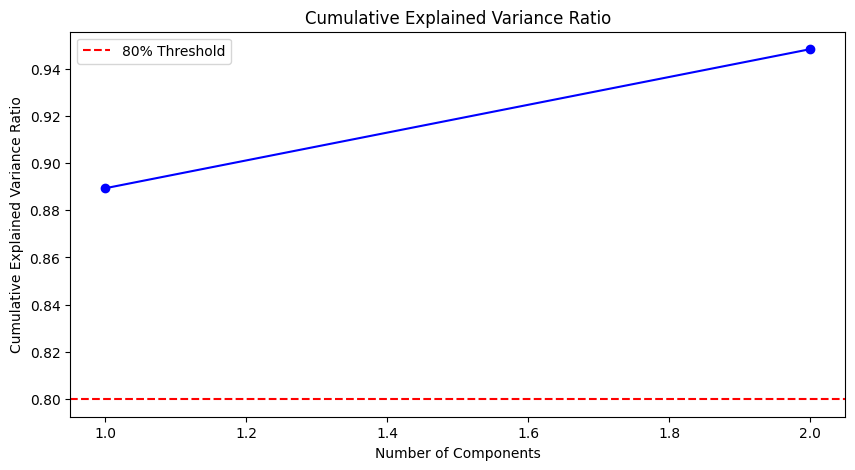

In [45]:
plot_cumulative_variance(pca)

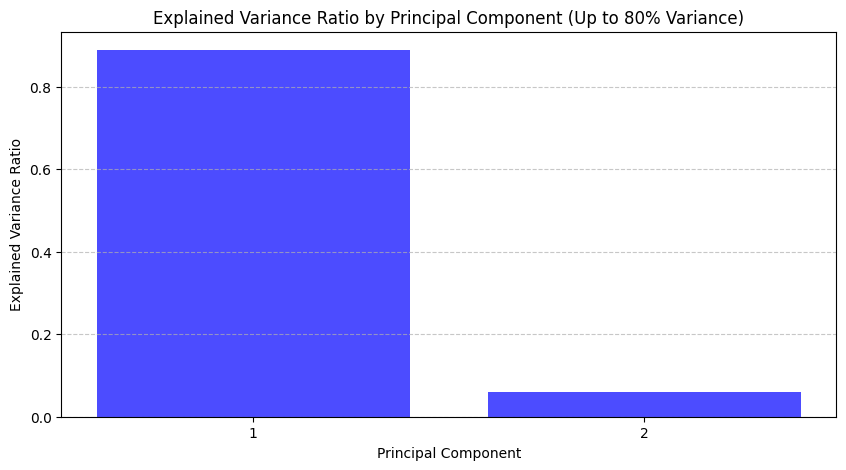

In [46]:
plot_explained_variance(pca, n_components)

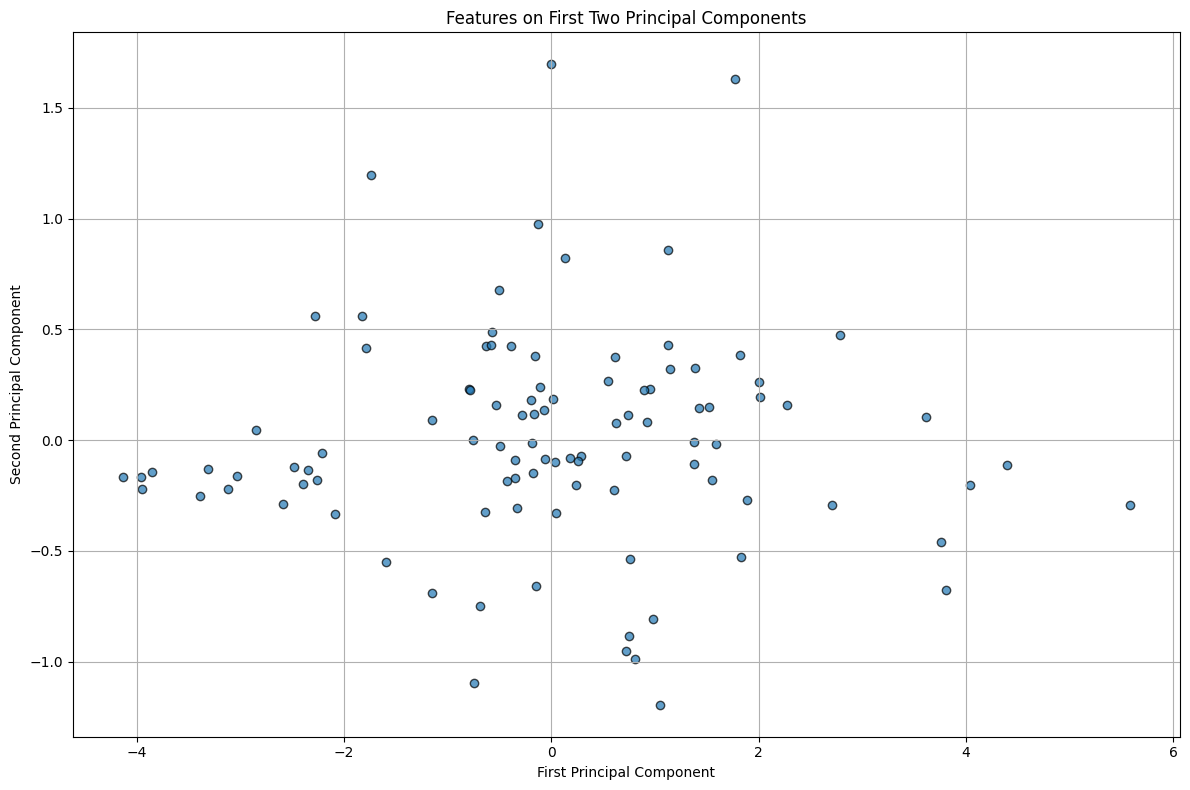

In [47]:
plot_pca_features(pca, X_pca, n_components)

In [48]:
loadings_df = plot_feature_loadings(pca, feature_names, n_components)
loadings_df


,PC1,PC2
r_mean,0.932431,0.347933
g_mean,0.982592,-0.019271
b_mean,0.936524,-0.340710
w_mean,0.938743,0.014482


In [49]:
loadings_df.sort_values(by="PC1", ascending=False).head(10)

,PC1,PC2
g_mean,0.982592,-0.019271
w_mean,0.938743,0.014482
b_mean,0.936524,-0.340710
r_mean,0.932431,0.347933



Step 9-12: Performing clustering analysis...


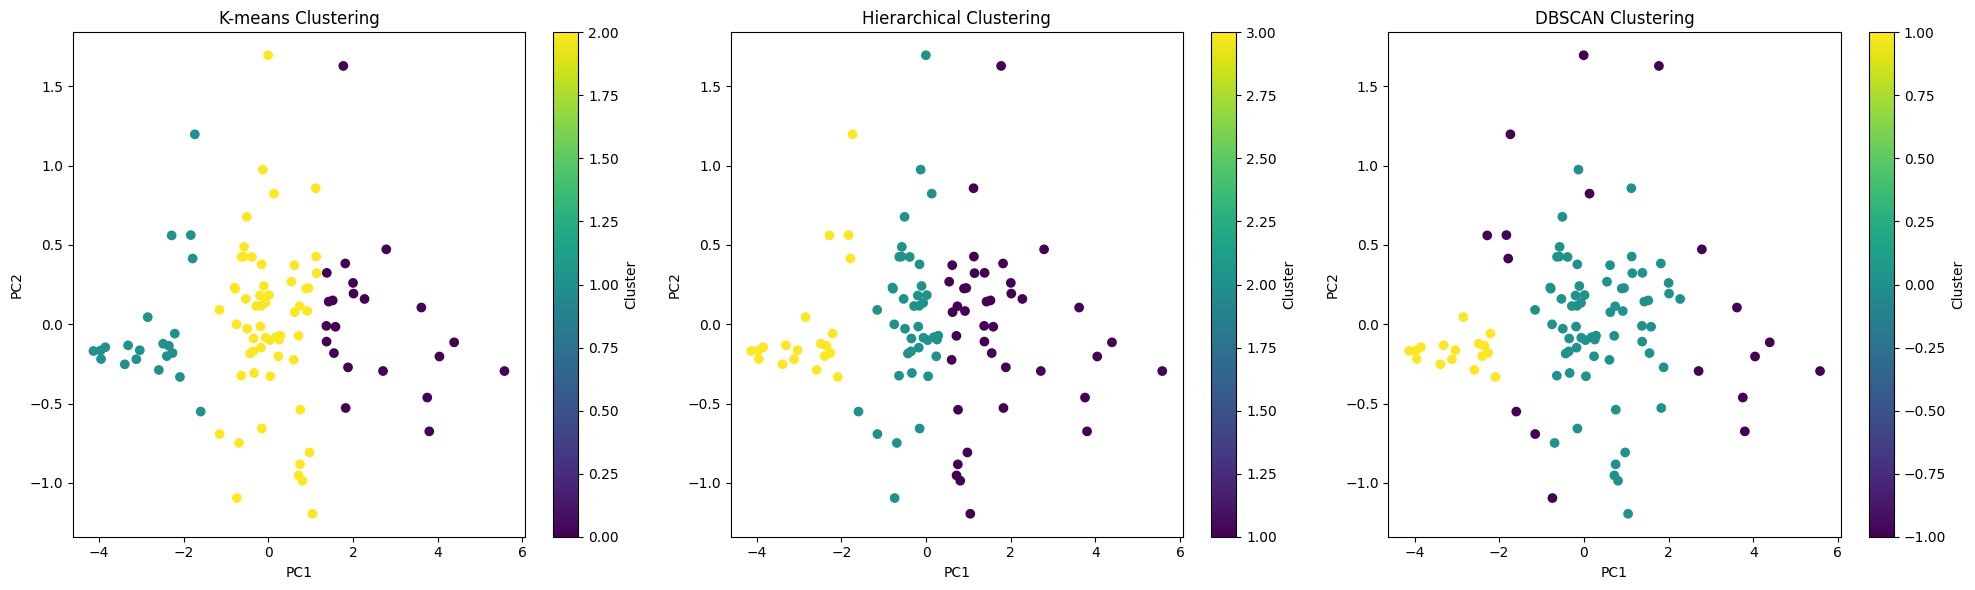

In [50]:
# 9-12. Clustering Analysis
print("\nStep 9-12: Performing clustering analysis...")
plot_clustering_comparison(X_pca, n_components)

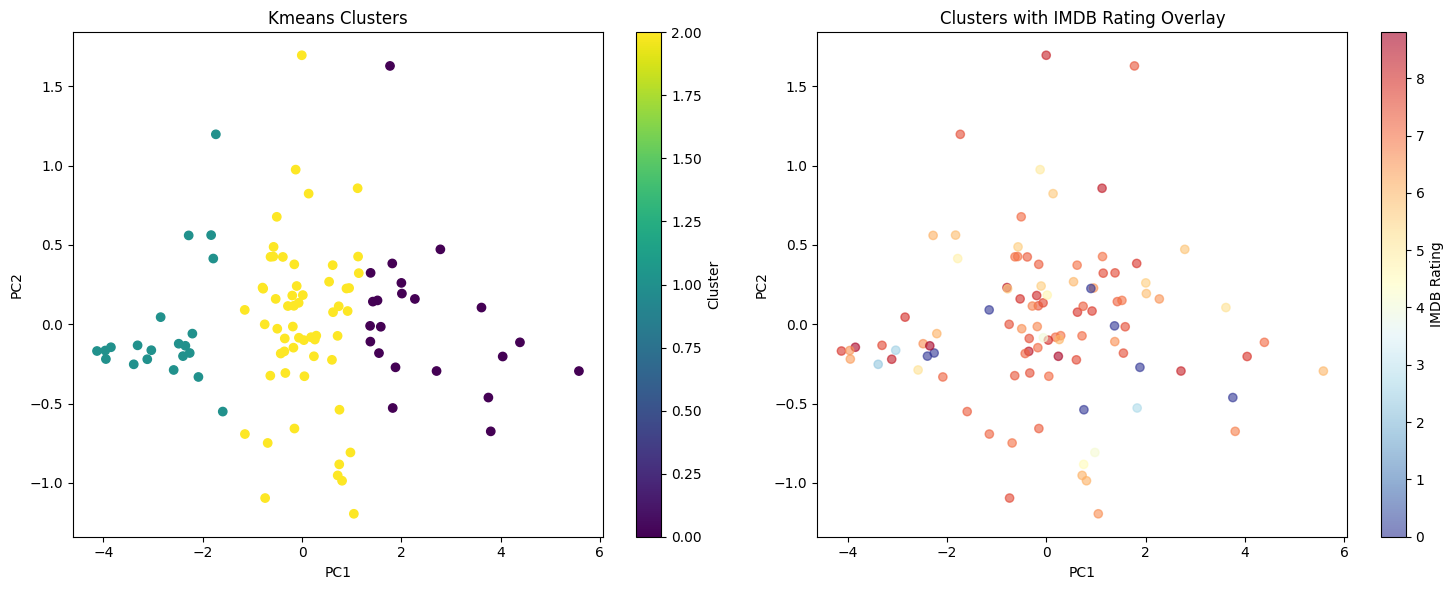


Cluster Statistics for IMDB Rating:
            mean      std  count
Cluster                         
0       5.745455 2.621291     22
1       5.890476 2.612835     21
2       6.543860 1.878451     57

One-way ANOVA test results:
F-statistic: 1.3382
p-value: 0.2671


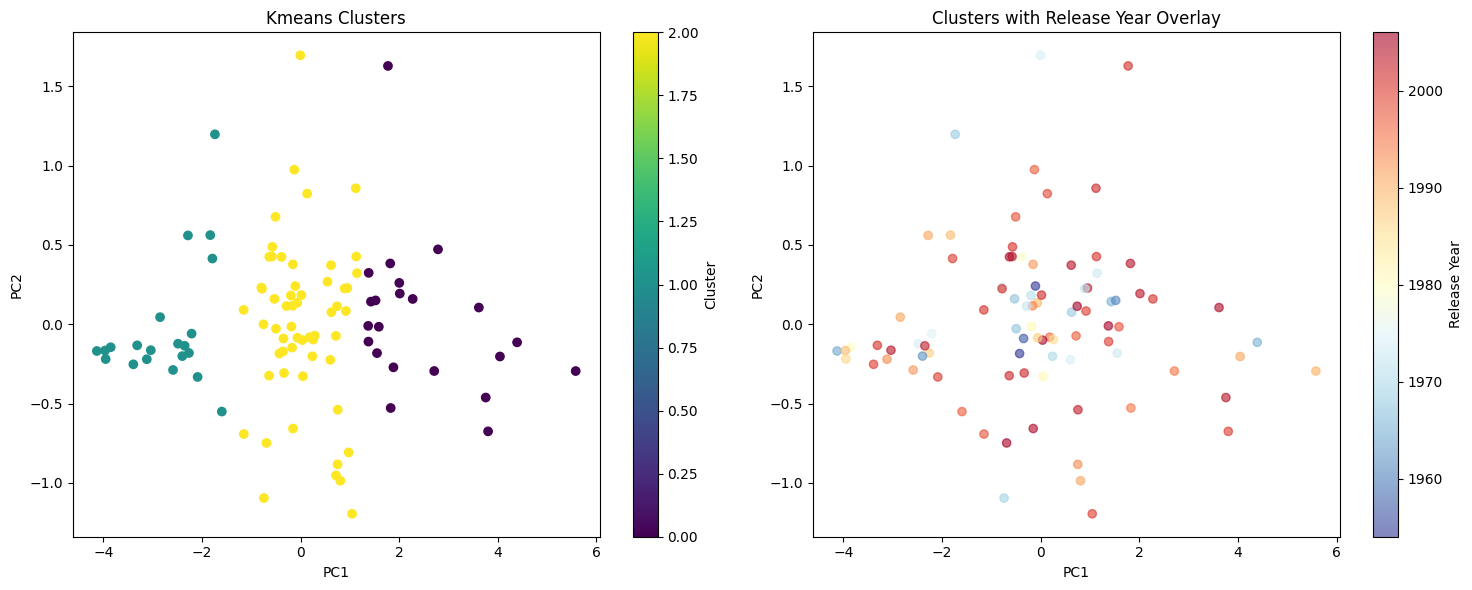


Cluster Statistics for Release Year:
               mean       std  count
Cluster                             
0       1992.111111 15.196319     18
1       1987.904762 12.864310     21
2       1988.460000 15.639054     50

One-way ANOVA test results:
F-statistic: nan
p-value: nan


In [51]:
# Extract year from date_published
imdb_df['year'] = pd.to_datetime(imdb_df['date_published']).dt.year

# Merge feature data with IMDB data
merged_df = pd.merge(feature_df, imdb_df, on='imdb_id')

# Visualize clusters with ratings
plot_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')
analyze_clusters_with_metadata(X_pca, merged_df['rating'], 'IMDB Rating')

# Visualize clusters with years
plot_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')
analyze_clusters_with_metadata(X_pca, merged_df['year'], 'Release Year')

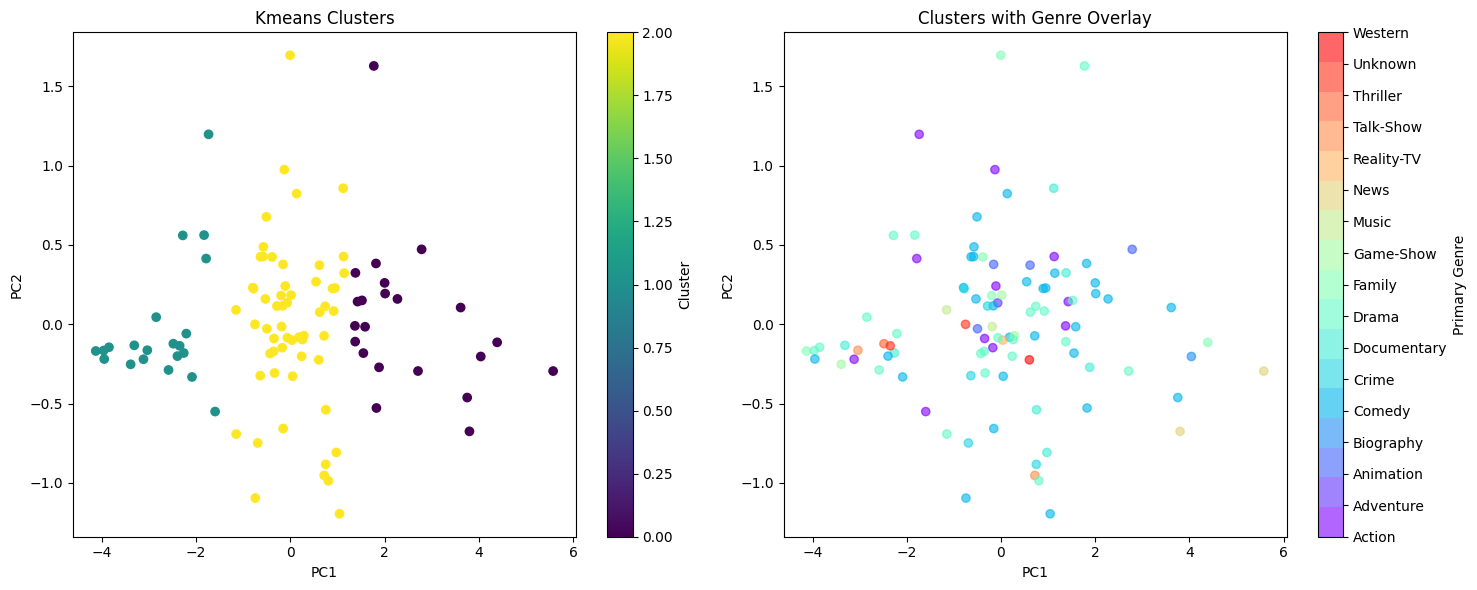


Genre Distribution across Clusters:

Percentage of genres in each cluster:
Genre      Action  Adventure  Animation  Biography    Comedy    Crime  \
Cluster                                                                 
0        9.090000   0.000000   4.550000   4.550000 40.910000 0.000000   
1       19.050000   0.000000   0.000000   0.000000 14.290000 0.000000   
2        8.770000   1.750000   5.260000   0.000000 31.580000 8.770000   

Genre    Documentary     Drama   Family  Game-Show    Music     News  \
Cluster                                                                
0           9.090000 18.180000 4.550000   0.000000 0.000000 9.090000   
1           9.520000 33.330000 4.760000   4.760000 0.000000 0.000000   
2           5.260000 19.300000 5.260000   3.510000 3.510000 0.000000   

Genre    Reality-TV  Talk-Show  Thriller  Unknown  Western  
Cluster                                                     
0          0.000000   0.000000  0.000000 0.000000 0.000000  
1          0.0

In [ ]:
# Visualize clusters with genres
plot_clusters_with_genres(X_pca, merged_df['genres'])
analyze_genre_distribution(X_pca, merged_df['genres'])